# **Week 9: Working with a Codebase** 
Recipe to apply a codebase to your data: 
**Find → Install → Import → Explore → Apply to your data**

We'll practise it on 2 packages (**scikit-learn**, **scanpy**) and 1 GitHub repo (**rastermap**).

## 1. Find the library you need
* Google **"python" + your task**: *"python PCA"*, *"python read EDF"*, *"python single cell RNA"*.
* Check the paper's **Code availability** section: most tools live on **GitHub**.
* Search **[pypi.org](https://pypi.org)**: everything you can `pip install` is listed there.
* What you shoudl be able to find: documentation, recent updates, answered *Issues* on GitHub.

| Your task | Library |
|---|---|
| PCA, clustering, classifiers | scikit-learn |
| single-cell / snRNA-seq | scanpy |
| EEG, `.edf` files | mne |
| MATLAB `.mat` files | scipy (`scipy.io.loadmat`) |
| sorting neurons by activity | rastermap (GitHub) |

## Example package: scikit-learn
**The website** ([scikit-learn.org](https://scikit-learn.org)): the top bar has **Install**, **User Guide** (explanations), **API** (Application Programming Interface, every function) and **Examples** (code with pictures).
Search *PCA* → open [`sklearn.decomposition.PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html). Every API page reads top to bottom:
**how to call it → Parameters (inputs) → Attributes (results) → Methods (what it can do) → Examples**.

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


After any `%pip install`, restart the kernel (*Kernel → Restart*).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

The same help text as on the website, right inside Jupyter:

In [3]:
PCA?

Init signature:
PCA(
    n_components=None,
    *,
    copy=True,
    whiten=False,
    svd_solver='auto',
    tol=0.0,
    iterated_power='auto',
    n_oversamples=10,
    power_iteration_normalizer='auto',
    random_state=None,
)
Docstring:     
Principal component analysis (PCA).

Linear dimensionality reduction using Singular Value Decomposition of the
data to project it to a lower dimensional space. The input data is centered
but not scaled for each feature before applying the SVD.

It uses the LAPACK implementation of the full SVD or a randomized truncated
SVD by the method of Halko et al. 2009, depending on the shape of the input
data and the number of components to extract.

With sparse inputs, the ARPACK implementation of the truncated SVD can be
used (i.e. through :func:`scipy.sparse.linalg.svds`). Alternatively, one
may consider :class:`TruncatedSVD` where the data are not centered.

Notice that this class only supports sparse inputs for some solvers such as
"arpack" and "c

In [4]:
recording = np.load('recording.npy')    
pca = PCA(n_components=10)
pca.fit(recording)

,n_components,10
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [5]:
[name for name in dir(pca) if not name.startswith('_')]    

['components_',
 'copy',
 'explained_variance_',
 'explained_variance_ratio_',
 'fit',
 'fit_transform',
 'get_covariance',
 'get_feature_names_out',
 'get_metadata_routing',
 'get_params',
 'get_precision',
 'inverse_transform',
 'iterated_power',
 'mean_',
 'n_components',
 'n_components_',
 'n_features_in_',
 'n_oversamples',
 'n_samples_',
 'noise_variance_',
 'power_iteration_normalizer',
 'random_state',
 'score',
 'score_samples',
 'set_output',
 'set_params',
 'singular_values_',
 'svd_solver',
 'tol',
 'transform',
 'whiten']

Text(0, 0.5, 'variance explained')

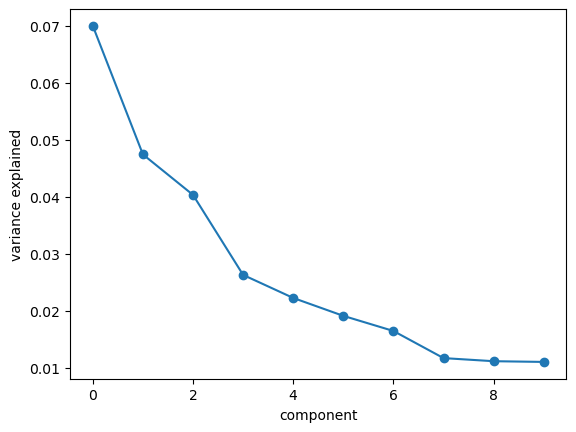

In [6]:
plt.plot(pca.explained_variance_ratio_, 'o-')
plt.xlabel('component'); plt.ylabel('variance explained')

**Try it:** on the PCA web page, find the **method** that gives the data in PC coordinates. Use it on `recording`. What shape do you get?

In [7]:
 # You need to transform the data to (480, 10) s.t. every stimulus is described by 10 numbers instead of ~11,000 neurons
# your code here
pcs = pca.transform(recording)
pcs.shape

(480, 10)

## Second example package - scanpy
**The website** ([scanpy.readthedocs.io](https://scanpy.readthedocs.io)): left menu has **Installation**, **Tutorials** and **API**.
The API has three main parts, and you use them in this order: `sc.pp` (preprocessing) → `sc.tl` (tools) → `sc.pl` (plots).

In [ ]:
%pip install scanpy

In [ ]:
import scanpy as sc
adata = sc.datasets.pbmc68k_reduced()     # small example that comes with scanpy.
# This dataset is a subset of the PBMC dataset from 10X Genomics. 
# It contains 68,000 cells and 183 features.
# The dataset is already preprocessed and normalized.
# The data is stored in an AnnData object, which is a sparse matrix of shape (cells, features).
# You can read your own data into an AnnData object using the sc.read_h5ad function.
# adata = sc.read_h5ad('your_file.h5ad')
adata

In [ ]:
sc.pl.umap(adata, color='bulk_labels') # bulk labels are the cell types.

**Example why API is useful:** in the API → Plotting section, find the **dot plot** function. Plot the genes `CD79A`, `LYZ`, `NKG7` grouped by `'bulk_labels'`.
This plot will show how much is each gene expressed in a cell type. 

In [ ]:
# your code here

## Third example: a GitHub repo - rastermap
Open [github.com/MouseLand/rastermap](https://github.com/MouseLand/rastermap) (same lab as last week's dataset). On any repo page:
* **README** (scroll down): what it does, how to install, a usage example.
* **Folders**: `rastermap/` is the code, `notebooks/` has worked examples.
* **Issues**: questions other people asked (and the answers).
* Green **Code** button → copy the link, or *Download ZIP* if you don't have git.

In [ ]:
!git clone --depth 1 https://github.com/MouseLand/rastermap.git      # --depth 1 = latest version only (1 MB instead of 74 MB)

In [ ]:
import os
os.listdir('rastermap'), os.listdir('rastermap/notebooks')       # same folders as on the website

In [ ]:
%pip install ./rastermap          # installs the downloaded folder (restart the kernel after)

The README says the input is **neurons × time**. Our `recording` is **stimuli × neurons**, so we transpose it with `.T`.

In [ ]:
from rastermap import Rastermap
from scipy.stats import zscore

spks = zscore(recording.T, axis=1)              # (neurons, stimuli)
model = Rastermap(n_PCs=100, n_clusters=50).fit(spks)
plt.imshow(spks[model.isort], aspect='auto', cmap='gray_r', vmin=0, vmax=1.5)
plt.xlabel('stimulus'); plt.ylabel('neurons (sorted by rastermap)')

**Try it:** open `rastermap/rastermap.py` on GitHub (or run `Rastermap?`). What does the `locality` parameter do?

In [ ]:
# your answer here